In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
df = pd.read_csv(r"D:\LinhNh\NLP\House_price\data\combined_house_prices.csv")
df.tail()

,street,ward,district,code_housing,date_update,price,price(m2),bedroom,bathroom,area(m2),direction,Label,description
9477,3 Tháng 2,phường 12,Quận 10,TUN56477,24/01/2026,15.5 tỷVND,688.89,5.00,6,22.50,NaN,NaN,"Bán nhà mặt tiền đường Ba tháng Hai, phường 12..."
9478,An Dương Vương,An Lạc,Bình Tân,TUN72137,24/01/2026,7.6 tỷVND,143.67,4.00,4,52.90,Đông Nam,NaN,Nhà phố hướng Đông Nam trong dự án Lux Ho...
9479,Đoàn Văn Bơ,Phường 14,Quận 4,TUN72330,24/01/2026,1.2 tỷVND,130.43,1.00,1,9.20,Tây Nam,NaN,"Nhà phố hướng Tây Nam, hẻm khu dân cư khé..."
9480,Đoàn Văn Bơ,Phường 16,Quận 4,TUN66287,24/01/2026,1.6 tỷVND,101.91,1.00,2,15.70,Đông Bắc,NaN,"Nhà phố Quận 4 hướng Bắc gồm 1 trệt 1 lầu, có ..."
9481,Chu Văn An,Phường 12,Bình Thạnh,TUN59200,24/01/2026,11 tỷVND -4%,74.48,4.00,3,147.70,Tây Nam,GIẢM GIÁ | GIẢM GIÁ,Bán nhà mặt tiền đường Chu Văn An hướng Tây Na...


In [76]:
# Loại bỏ mọi thứ từ " -" trở đi (bao gồm khoảng trắng trước dấu -)
df["price"] = df["price"].str.split(" -").str[0].str.strip()

In [77]:
# Hoặc cách 2: Đơn giản hơn nếu dữ liệu khá đồng nhất
df["price"] = (
    df["price"]
    .str.replace(" tỷVND", "", regex=False)
    .str.replace("tỷVND", "", regex=False)
    .str.replace(" tỷ", "", regex=False)
    .str.strip()
)

In [78]:
unique_prices = df["price"].unique()  # cách hay nhất & phổ biến nhất
unique_prices

array(['12.5', '16.1', '9.3', '15.2', '20', '22', '29', '14.5', '36',
       '33', '32.5', '19', '28.6', '24.5', '5.8', '3', '16', '38.97',
       '42.23', '54', '16.9', '14.9', '18.9', '13.49', '89', '6.3', '50',
       '52', '70', '45', '48', '39.5', '23.5', '54.21', '18', '10.6',
       '14', '4.5', '3.4', '7.8', '1.7', '56.65', '51.52', '10.5',
       '27.85', '48.68', '48.32', '53.56', '32.4', '13.5', '81', '24.8',
       '19.7', '6.2', '6', '8.8', '4.8', '5.2', '8', '4', '1.4', '5.4',
       '7.2', '30', '4.2', '19.5', '18.59', '20.61', '25', '17', '21.5',
       '13', '9.1', '6.9', '9', '65', '9.5', '3.05', '5.3', '27.5', '7',
       '13.45', '24', '5', '5.7', '2.1', '3.1', '4.98', '7.5', '4.6',
       '3.6', '9.58', '6.45', '4.68', '4.7', '3.3', '3.5', '5.85', '4.3',
       '4.1', '11', '6.5', '3.9', '2.45', '16.5', '12', '11.9', '29.6',
       '23', '5.5', '7.9', '10.7', '11.8', '3.85', '7.55', '5.6', '3.98',
       '5.68', '3.8', '10.9', '5.65', '31', '4.95', '6.8', '82.5', '

In [79]:
df.info

<bound method DataFrame.info of               street           ward    district code_housing date_update  \
0           Phan Ngữ         Đa Kao      Quận 1    T01199189  23/01/2026   
1        Nguyễn Xiển  Long Thạnh Mỹ      Quận 9    T09160912  23/01/2026   
2      Điện Biên Phủ      Phường 17  Bình Thạnh    TBT199076  23/01/2026   
3         Tỉnh Lộ 41      Thạnh Lộc     Quận 12    T12199064  23/01/2026   
4         Phùng Hưng      Phường 14      Quận 5    T05198560  23/01/2026   
...              ...            ...         ...          ...         ...   
9477       3 Tháng 2      phường 12     Quận 10     TUN56477  24/01/2026   
9478  An Dương Vương         An Lạc    Bình Tân     TUN72137  24/01/2026   
9479     Đoàn Văn Bơ      Phường 14      Quận 4     TUN72330  24/01/2026   
9480     Đoàn Văn Bơ      Phường 16      Quận 4     TUN66287  24/01/2026   
9481      Chu Văn An      Phường 12  Bình Thạnh     TUN59200  24/01/2026   

     price  price(m2)  bedroom  bathroom  area(m2) dire

In [80]:
df.columns

Index(['street', 'ward', 'district', 'code_housing', 'date_update', 'price',
       'price(m2)', 'bedroom', 'bathroom', 'area(m2)', 'direction', 'Label',
       'description'],
      dtype='object')

In [81]:
del df["direction"]

In [82]:
df.isna().sum()

street             0
ward               0
district           0
code_housing       0
date_update        0
price              0
price(m2)          0
bedroom            4
bathroom           0
area(m2)           0
Label           7916
description        2
dtype: int64

In [83]:
df = df.dropna(subset=["bedroom", "description"])

In [84]:
df['Label'] = df['Label'].fillna(0) 


C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\4207983195.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [85]:
# Xử lý price: loại bỏ '% ' và chuyển sang số (tỷ VND -> VND)
df["price"] = df["price"].str.replace(r" -?\d+%", "", regex=True)
df["price_numeric"] = df["price"].str.extract(r"(\d+\.?\d*)")[0].astype(float) * 1e9

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\3918356710.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\3918356710.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [86]:
df.isna().sum()

street           0
ward             0
district         0
code_housing     0
date_update      0
price            0
price(m2)        0
bedroom          0
bathroom         0
area(m2)         0
Label            0
description      0
price_numeric    0
dtype: int64

In [87]:
unique_districts = df["district"].unique()
print(unique_districts)

['Quận 1' 'Quận 9' 'Bình Thạnh' 'Quận 12' 'Quận 5' 'Thủ Đức' 'Hồ Chí Minh'
 'Quận 3' 'Quận 11' 'Nhà Bè' 'Quận 2' 'Quận 7' 'Quận 4' 'Gò Vấp' 'Quận 6'
 'Quận 10' 'Quận 8' 'Tân Bình' 'Bình Chánh' 'Tân Phú' 'Bình Tân'
 'Phú Nhuận' 'Hóc Môn' 'Củ Chi']


In [88]:
# Lọc bỏ những dòng có district bằng đúng chữ "Hồ Chí Minh"
df = df[df["district"] != "Hồ Chí Minh"]

===================================================================================================================================================================

### Biểu đồ phân bố số lượng bất động sản theo quận/huyện

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\1375665824.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




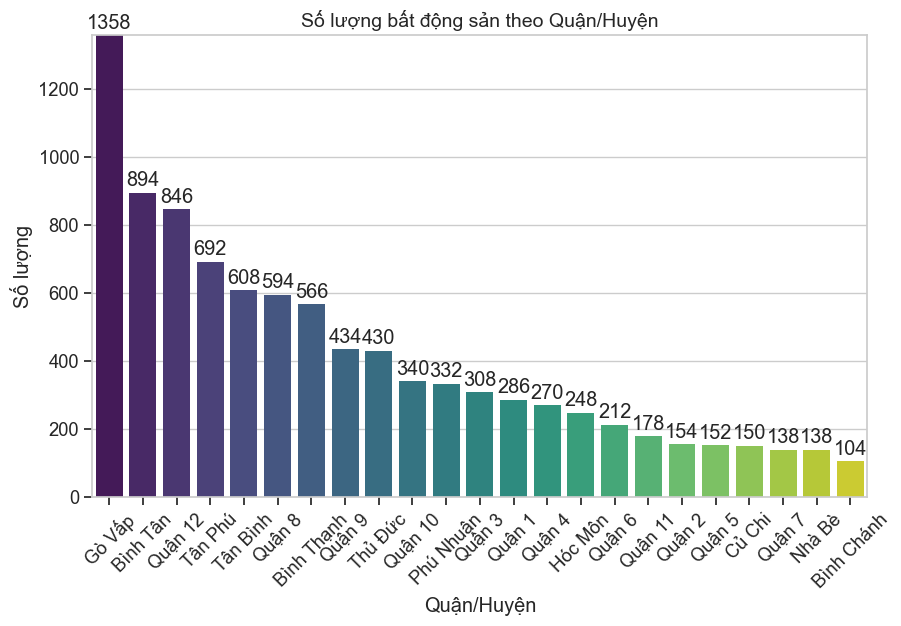

In [ ]:
# 2. Thống kê số lượng theo từng Quận/Huyện
district_counts = df["district"].value_counts().reset_index()
district_counts.columns = ["district", "count"]

# 3. Vẽ biểu đồ cột
plt.figure(figsize=(10, 6))
ax = sns.barplot(x="district", y="count", data=district_counts, palette="viridis")

# 4. Hiển thị số lượng cụ thể trên đầu mỗi cột
for p in ax.patches:
    ax.annotate(
        format(p.get_height(), ".0f"),
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 9),
        textcoords="offset points",
    )

# 5. Thêm tiêu đề và nhãn
plt.title("Số lượng bất động sản theo Quận/Huyện", fontsize=14)
plt.xlabel("Quận/Huyện")
plt.ylabel("Số lượng")
plt.ylim(
    0, district_counts["count"].max() + 1
)  # Tạo thêm khoảng trống phía trên để không bị đè số
plt.xticks(rotation=45)

plt.show()

### Nhận xét chính về phân bố số lượng bất động sản theo quận/huyện

- **Quận Gò Vấp dẫn đầu tuyệt đối** với **1.358 bất động sản**, vượt trội rõ rệt so với tất cả các khu vực khác và giữ vị trí số 1 một cách áp đảo.

#### Nhóm dẫn đầu (trên 600 căn)
**5 quận/huyện này chiếm tỷ trọng lớn nhất** trong toàn bộ dữ liệu:
- **Gò Vấp**: **1.358**
- **Bình Tân**: **894**
- **Quận 12**: **846**
- **Tân Phú**: **692**
- **Tân Bình**: **608**

#### Nhóm trung bình cao (500–600 căn)
- **Bình Thạnh**: **566**
- **Quận 8**: **594**  
→ Vẫn duy trì mức độ hoạt động khá cao và ổn định.

#### Nhóm trung bình (200–500 căn)
Nhóm này chiếm phần lớn số lượng quận/huyện, nhưng giá trị riêng lẻ đã giảm đáng kể so với nhóm dẫn đầu:
- Quận 9: **434**
- … (các quận/huyện khác)
- Hóc Môn: **248**

#### Mức thấp nhất
- **Bình Chánh**: chỉ đạt **104 bất động sản**  
  → **Khu vực có số lượng bất động sản thấp nhất** trong toàn bộ tập dữ liệu.

===========================================================================================================================================

### Biểu đồ phân bố số lượng nhà theo khoảng giá (tỷ VND)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\1258845667.py:29: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




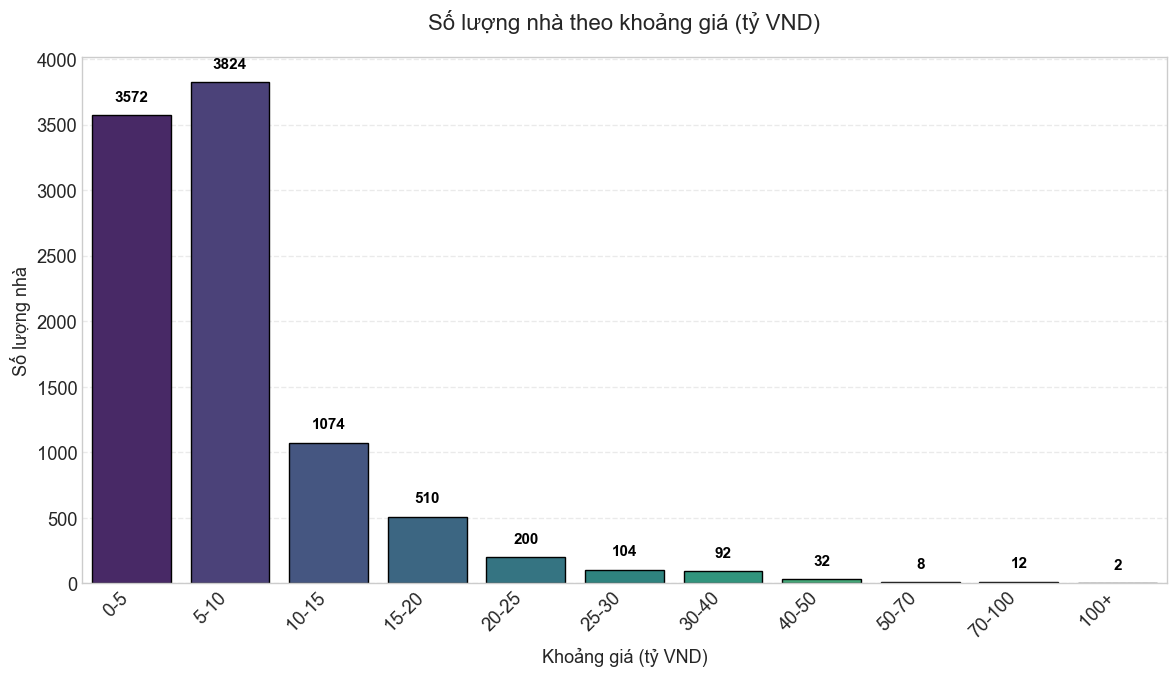

In [ ]:

df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Chia khoảng giá (có thể điều chỉnh bins theo ý bạn)
bins = [0, 5, 10, 15, 20, 25, 30, 40, 50, 70, 100, 150]
labels = [
    "0-5",
    "5-10",
    "10-15",
    "15-20",
    "20-25",
    "25-30",
    "30-40",
    "40-50",
    "50-70",
    "70-100",
    "100+",
]
df["price_bin"] = pd.cut(
    df["price"], bins=bins, right=False, labels=labels, include_lowest=True
)

# Biểu đồ
plt.figure(figsize=(12, 7))
ax = sns.countplot(
    data=df, x="price_bin", order=labels, palette="viridis", edgecolor="black"
)

plt.title("Số lượng nhà theo khoảng giá (tỷ VND)", fontsize=16, pad=20)
plt.xlabel("Khoảng giá (tỷ VND)", fontsize=13)
plt.ylabel("Số lượng nhà", fontsize=13)
plt.xticks(rotation=45, ha="right")

# Ghi số lượng lên đầu mỗi cột
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        xytext=(0, 8),  # khoảng cách phía trên cột
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black",
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Phân bố số lượng nhà theo khoảng giá (tỷ VND)

Biểu đồ thể hiện sự **tập trung cực kỳ mạnh** vào phân khúc **giá thấp và trung bình**, với lượng nhà giảm dần mạnh mẽ khi giá tăng cao. Thị trường bất động sản trong dữ liệu chủ yếu phục vụ nhu cầu phổ thông, trong khi phân khúc cao cấp và siêu cao cấp chiếm tỷ lệ rất nhỏ.

#### Nhận xét chính

- **Phân khúc phổ biến nhất & dẫn đầu tuyệt đối**:  
  **Khoảng giá 5–10 tỷ** đạt **3.824 căn** – **cao nhất toàn bộ dữ liệu**, vượt trội so với các khoảng khác.  
  Tiếp theo là **0–5 tỷ** với **3.572 căn** – gần tương đương, cho thấy **hai phân khúc dưới 10 tỷ thống trị hoàn toàn thị trường**.

- **Tổng hợp phân khúc dưới 10 tỷ** (phân khúc phổ thông):  
  **3.572 + 3.824 = 7.396 căn**  
  → **Chiếm khoảng 78.4% tổng số nhà** trong dữ liệu (tổng cộng ≈ 9.430 căn).

- **Phân khúc trung bình cao (10–20 tỷ)**:  
  - 10–15 tỷ: **1.074 căn**  
  - 15–20 tỷ: **510 căn**  
  → **Tổng ≈ 1.584 căn** (chiếm **16.8%**)  
  → Vẫn có lượng giao dịch đáng kể nhưng **giảm mạnh** so với nhóm dưới 10 tỷ.

- **Phân khúc cao cấp & siêu cao cấp (trên 20 tỷ)**:  
  - 20–25 tỷ: **200 căn**  
  - 25–30 tỷ: **104 căn**  
  - 30–40 tỷ: **92 căn**  
  - 40–50 tỷ: **32 căn**  
  - 50–70 tỷ: **8 căn**  
  - 70–100 tỷ: **12 căn**  
  - **Trên 100 tỷ**: chỉ **2 căn**  
  → **Tổng trên 20 tỷ ≈ 450 căn** (chỉ chiếm **4.8%** tổng lượng)  
  → Phân khúc cao cấp có **tỷ trọng rất thấp**, cho thấy thị trường chủ yếu hướng đến người mua có thu nhập trung bình và trung bình khá.

- **Phân khúc ít nhất / kém hấp dẫn nhất**:  
  **Trên 100 tỷ** chỉ có **2 căn** – **thấp nhất toàn bộ tập dữ liệu**, phản ánh nhu cầu cực kỳ hạn chế ở mức giá siêu cao cấp.

#### Kết luận tổng quan
Thị trường bất động sản trong dữ liệu này **rất tập trung vào phân khúc giá dưới 10 tỷ** (chiếm gần 80%), phù hợp với nhu cầu nhà ở thực tế của đa số người dân. Phân khúc trung bình cao (10–20 tỷ) vẫn có chỗ đứng nhất định, trong khi **phân khúc trên 20 tỷ** chỉ chiếm tỷ lệ rất nhỏ, đặc biệt là các mức giá siêu cao cấp gần như không đáng kể.

===========================================================================================================================================================

### Biểu đồ: Giá trung bình/m² theo Quận/Huyện (triệu VND)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\3176584624.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




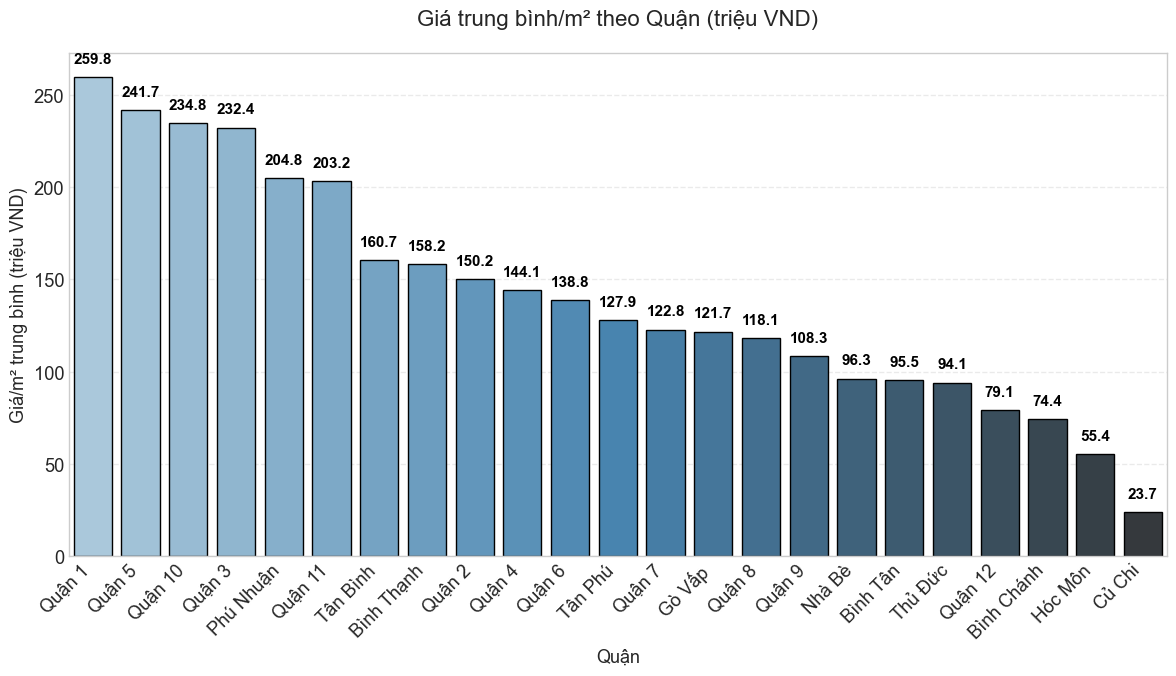

In [97]:
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=df,
    x="district",
    y="price(m2)",
    estimator="mean",
    errorbar=None,  # bỏ error bar nếu muốn sạch sẽ
    order=df.groupby("district")["price(m2)"].mean().sort_values(ascending=False).index,
    palette="Blues_d",
    edgecolor="black",
)

plt.title("Giá trung bình/m² theo Quận (triệu VND)", fontsize=16, pad=20)
plt.xlabel("Quận", fontsize=13)
plt.ylabel("Giá/m² trung bình (triệu VND)", fontsize=13)
plt.xticks(rotation=45, ha="right")

# Ghi giá trị trung bình lên đầu cột (làm tròn 1 chữ số thập phân)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{height:.1f}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black",
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Giá trung bình/m² theo Quận/Huyện (triệu VND)

Biểu đồ cho thấy **sự chênh lệch giá cực kỳ lớn** giữa các quận/huyện tại TP.HCM, phản ánh rõ nét sự phân cấp vị trí địa lý, mức độ đô thị hóa, tiện ích hạ tầng và giá trị bất động sản. Giá trung bình/m² giảm dần mạnh mẽ từ trung tâm lịch sử ra ngoại thành.

#### Nhận xét chính

- **Quận có giá cao nhất & dẫn đầu tuyệt đối**:  
  **Quận 1** đạt **259,8 triệu VND/m²** – **cao nhất toàn bộ dữ liệu**, vượt trội đáng kể so với các quận còn lại và khẳng định vị thế trung tâm tài chính – thương mại hàng đầu.

- **Nhóm dẫn đầu (trên 200 triệu/m²)** – Các quận trung tâm truyền thống:  
  - **Quận 1**: **259,8**  
  - **Quận 5**: **241,7**  
  - **Quận 10**: **234,8**  
  - **Quận 3**: **232,4**  
  → Đây là **lõi nội thành lịch sử**, nơi tập trung giá trị đất đai cao nhất, nhu cầu cao cấp và đầu tư mạnh.

- **Nhóm cao cấp (150–200 triệu/m²)** – Nội thành và vùng chuyển tiếp:  
  - **Phú Nhuận**: **204,8**  
  - **Quận 11**: **203,2**  
  - **Tân Bình**: **160,7**  
  - **Bình Thạnh**: **158,2**  
  - **Quận 2** (nay thuộc TP. Thủ Đức): **150,2**  
  → Vẫn duy trì mức giá cao, nhờ vị trí gần trung tâm và hạ tầng phát triển tốt.

- **Nhóm trung bình (100–150 triệu/m²)** – Các quận đang phát triển hoặc vùng ven trung tâm:  
  - **Quận 4**: **144,1**  
  - **Quận 6**: **138,8**  
  - **Tân Phú**: **127,9**  
  - **Quận 7**: **122,8**  
  - **Gò Vấp**: **121,7**  
  - **Quận 8**: **118,1**  
  → Chiếm tỷ lệ lớn, đại diện cho phân khúc nhà ở phổ thông – trung cấp, có tiềm năng tăng giá trong tương lai.

- **Nhóm thấp (dưới 100 triệu/m²)** – Chủ yếu ngoại thành và vùng ven:  
  - **Quận 9** (nay thuộc TP. Thủ Đức): **108,3**  
  - **Nhà Bè**: **96,3**  
  - **Bình Tân**: **95,5**  
  - **Thủ Đức** (cũ): **94,1**  
  - **Quận 12**: **79,1**  
  - **Bình Chánh**: **74,4**  
  - **Hóc Môn**: **55,4**  
  - **Củ Chi**: **23,7**  
  → Phân khúc này phù hợp với nhu cầu nhà ở giá rẻ, đất nền rộng hoặc đầu tư dài hạn.

- **Quận/Huyện có giá thấp nhất**:  
  **Huyện Củ Chi** chỉ đạt **23,7 triệu VND/m²** – **thấp nhất toàn bộ dữ liệu**.  
  → Chênh lệch với Quận 1 khoảng **11 lần** (259,8 / 23,7 ≈ 10,96), minh chứng rõ nét cho sự phân cực giá bất động sản theo vị trí địa lý tại TP.HCM.

#### Kết luận tổng quan
Thị trường bất động sản TP.HCM thể hiện **sự phân cấp rõ rệt**:  
- **Trung tâm nội thành** (Quận 1, 3, 5, 10) giữ vững vị thế giá cao nhất, hướng đến phân khúc cao cấp và đầu tư.  
- **Vùng ven và ngoại thành** có giá thấp hơn nhiều, phù hợp nhu cầu ở thực và đầu tư dài hạn.  
Sự chênh lệch lên đến hơn 10 lần giữa trung tâm và ngoại ô là đặc trưng nổi bật, phản ánh mức độ phát triển không đồng đều và giá trị vị trí tại thành phố lớn nhất Việt Nam.

===================================================================================================================================================================

### Biểu đồ: Phân bố số lượng nhà theo khoảng giá (tỷ VND)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\810579015.py:2: UserWarning:

Ignoring `palette` because no `hue` variable has been assigned.



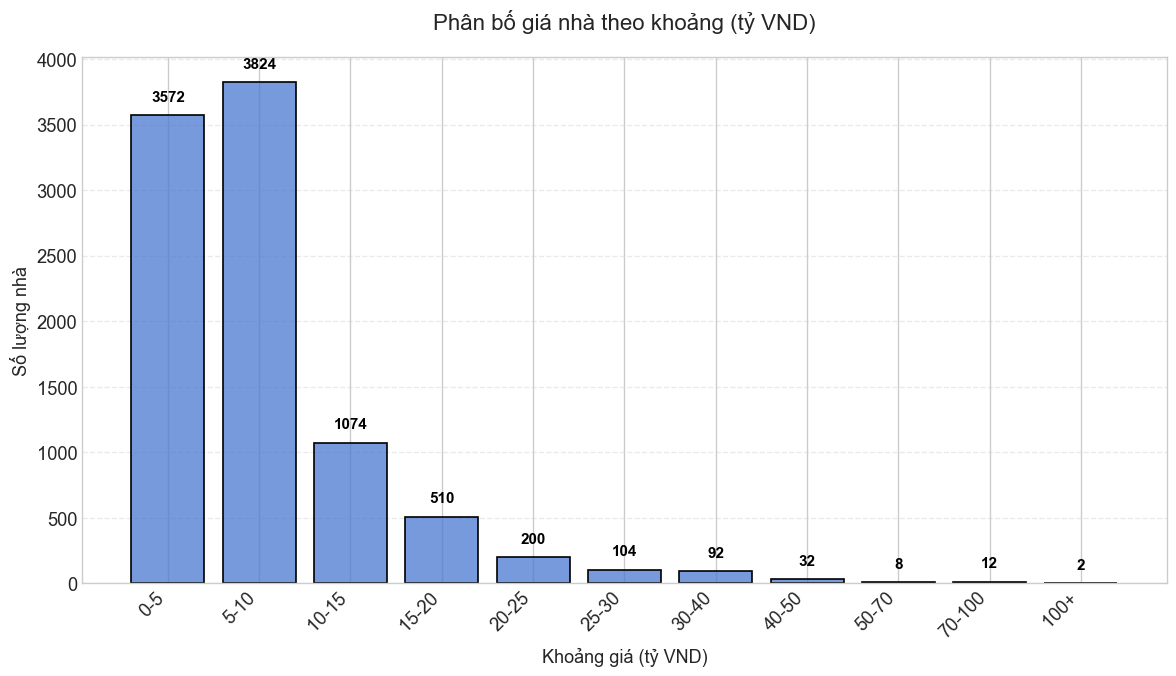

In [98]:
plt.figure(figsize=(12, 7))
ax = sns.histplot(
    data=df,
    x="price_bin",
    discrete=True,
    shrink=0.8,
    edgecolor="black",
    linewidth=1.2,
    palette="viridis",
)

plt.title("Phân bố giá nhà theo khoảng (tỷ VND)", fontsize=16, pad=20)
plt.xlabel("Khoảng giá (tỷ VND)", fontsize=13)
plt.ylabel("Số lượng nhà", fontsize=13)
plt.xticks(rotation=45, ha="right")

# Ghi số lượng lên đầu mỗi cột
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        xytext=(0, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
        color="black",
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Phân bố số lượng nhà theo khoảng giá (tỷ VND)

Biểu đồ phản ánh rõ nét đặc trưng của thị trường bất động sản TP.HCM: **phân bố giá nhà tập trung cực kỳ mạnh** vào phân khúc **thấp và trung bình**, trong khi lượng nhà giảm sút nhanh chóng và mạnh mẽ khi giá tăng lên mức cao cấp và siêu cao cấp. Điều này cho thấy thị trường chủ yếu phục vụ nhu cầu ở thực của đa số người mua có thu nhập trung bình và trung bình khá.

#### Nhận xét chính

- **Phân khúc được ưa chuộng nhất & dẫn đầu tuyệt đối**:  
  **Khoảng giá 5–10 tỷ** đạt **3.824 căn** – **cao nhất toàn bộ dữ liệu**, vượt trội so với các khoảng khác và là lựa chọn phổ biến nhất trên thị trường.  
  Tiếp theo sát nút là **0–5 tỷ** với **3.572 căn**, khẳng định **hai phân khúc dưới 10 tỷ thống trị hoàn toàn** thị trường.

- **Tổng hợp phân khúc phổ thông (dưới 10 tỷ)**:  
  **3.572 + 3.824 = 7.396 căn**  
  → **Chiếm khoảng 78–80% tổng số lượng nhà** trong toàn bộ dữ liệu (tổng ước tính ≈ 9.400–9.500 căn), minh chứng cho sức hút vượt trội của phân khúc giá phải chăng.

- **Phân khúc trung bình cao (10–20 tỷ)**:  
  - 10–15 tỷ: **1.074 căn**  
  - 15–20 tỷ: **510 căn**  
  → **Tổng ≈ 1.584 căn** (chiếm khoảng 16–17%)  
  → Vẫn duy trì lượng giao dịch đáng kể, nhưng **giảm mạnh** (chỉ bằng khoảng 21% so với nhóm dưới 10 tỷ), phù hợp với nhóm khách hàng có thu nhập khá trở lên.

- **Phân khúc cao cấp & siêu cao cấp (trên 20 tỷ)**:  
  - 20–25 tỷ: **200 căn**  
  - 25–30 tỷ: **104 căn**  
  - 30–40 tỷ: **92 căn**  
  - 40–50 tỷ: **32 căn**  
  - 50–70 tỷ: **8 căn**  
  - 70–100 tỷ: **12 căn**  
  - **Trên 100 tỷ**: chỉ **2 căn**  
  → **Tổng trên 20 tỷ ≈ 450 căn** (chỉ chiếm **dưới 5%** toàn bộ dữ liệu)  
  → Phân khúc cao cấp có **tỷ trọng rất thấp**, đặc biệt các mức giá siêu cao cấp gần như không đáng kể.

- **Phân khúc ít hấp dẫn nhất**:  
  **Trên 100 tỷ** chỉ có **2 căn** – **thấp nhất toàn bộ dữ liệu**, gần như không tồn tại trên thị trường đại chúng, phản ánh nhu cầu cực kỳ hạn chế ở phân khúc siêu sang.

#### Kết luận tổng quan
Thị trường bất động sản trong dữ liệu này **rất thiên về phân khúc giá dưới 10 tỷ** (chiếm gần 80%), tập trung vào nhu cầu nhà ở thực tế, nhà ở lần đầu hoặc nâng cấp vừa phải. Phân khúc trung bình cao (10–20 tỷ) vẫn có chỗ đứng nhất định, trong khi **phân khúc trên 20 tỷ** chỉ chiếm tỷ lệ rất nhỏ, cho thấy thị trường chủ yếu hướng đến người mua phổ thông và trung lưu, ít phục vụ nhóm khách hàng thượng lưu hoặc đầu tư cao cấp.  
Sự suy giảm nhanh chóng theo mức giá càng cao càng khẳng định tính chất **thực dụng** và **phổ thông** của thị trường bất động sản hiện tại.

==========================================================================================================================================================

### Biểu đồ: Top 10 Quận/Huyện có nhiều nhà rao bán nhất

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\3339780030.py:11: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




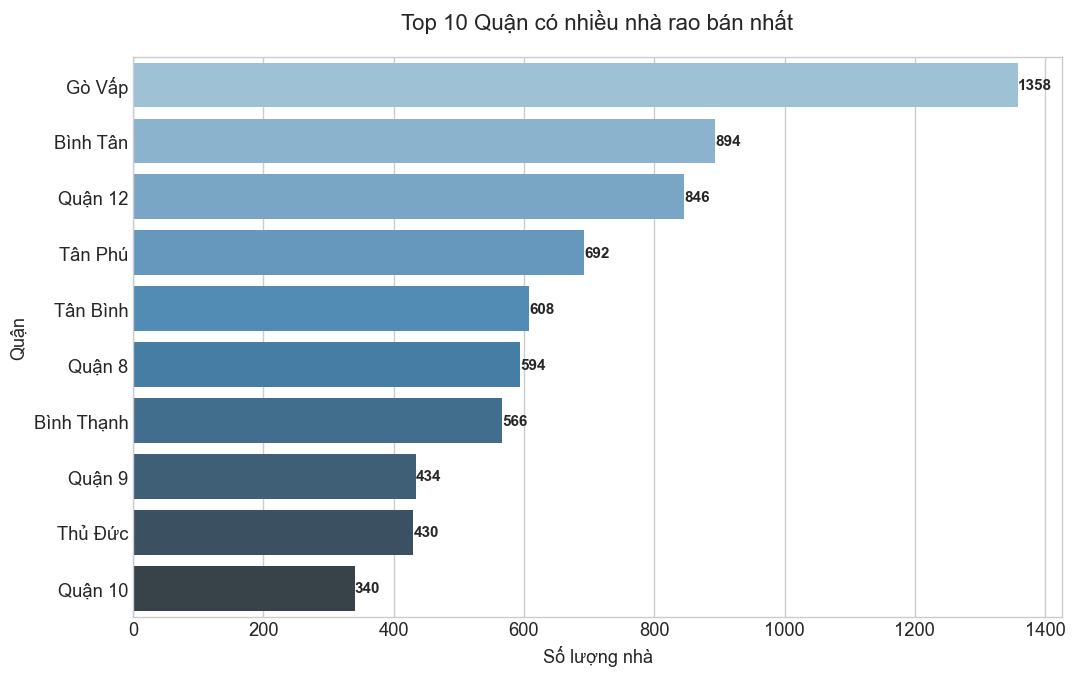

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

top_district = df["district"].value_counts().head(10)

plt.figure(figsize=(11, 7))
ax = sns.barplot(x=top_district.values, y=top_district.index, palette="Blues_d")

plt.title("Top 10 Quận có nhiều nhà rao bán nhất", fontsize=16, pad=20)
plt.xlabel("Số lượng nhà", fontsize=13)
plt.ylabel("Quận", fontsize=13)

for i, v in enumerate(top_district.values):
    ax.text(v + 0.3, i, f"{int(v)}", va="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Top 10 Quận/Huyện có nhiều nhà rao bán nhất

Biểu đồ xếp hạng Top 10 quận/huyện theo số lượng nhà rao bán cho thấy **sự tập trung nguồn cung rõ rệt** vào một nhóm quận dẫn đầu, chủ yếu là các quận ngoại thành và vùng ven đang phát triển mạnh về dân cư và nhà ở phổ thông. Điều này phản ánh nhu cầu nhà ở thực tế cao ở các khu vực có giá phải chăng và quỹ đất còn tương đối dồi dào.

#### Nhận xét chính

- **Quận dẫn đầu & vượt trội tuyệt đối**:  
  **Gò Vấp** đứng đầu với **1.358 nhà rao bán** – **con số cao nhất toàn bộ dữ liệu**, vượt xa các quận còn lại và khẳng định vị thế số 1 về nguồn cung nhà ở tại TP.HCM.

- **Nhóm dẫn đầu (trên 800 căn)** – Ba quận thống trị Top 3:  
  - **Gò Vấp**: **1.358**  
  - **Bình Tân**: **894**  
  - **Quận 12**: **846**  
  → **Ba quận này chiếm tỷ trọng lớn nhất** trong Top 10, tạo thành nhóm nguồn cung chính, chủ yếu là các quận ngoại thành có dân số đông và tốc độ đô thị hóa nhanh.

- **Nhóm cao (500–700 căn)** – Nguồn cung dồi dào, thanh khoản tốt:  
  - **Tân Phú**: **692**  
  - **Tân Bình**: **608**  
  - **Quận 8**: **594**  
  - **Bình Thạnh**: **566**  
  → Nhóm này vẫn duy trì lượng rao bán đáng kể, phản ánh sự sôi động của thị trường nhà ở trung cấp và khu vực gần trung tâm.

- **Nhóm trung bình (300–500 căn)** – Vẫn nằm trong Top 10 nhưng giảm dần:  
  - **Quận 9** (nay thuộc TP. Thủ Đức): **434**  
  - **Thủ Đức** (cũ): **430**  
  - **Quận 10**: **340**  
  → Lượng rao bán giảm rõ rệt so với nhóm đầu, nhưng vẫn đủ để lọt Top 10.

#### Các chỉ số nổi bật
- **Gò Vấp vượt Bình Tân (thứ 2) khoảng 52%** (1.358 so với 894) – khoảng cách rất lớn, cho thấy sự vượt trội hoàn toàn của Gò Vấp.  
- **Top 3 quận (Gò Vấp, Bình Tân, Quận 12)** chiếm **hơn 50% tổng số lượng nhà rao bán trong Top 10**, minh chứng cho sự tập trung nguồn cung vào các quận ngoại thành phổ thông.  
- **Quận 10** – dù là quận trung tâm truyền thống – chỉ xếp **thứ 10** với **340 căn**, thấp hơn đáng kể so với các quận vùng ven, phản ánh nguồn cung nhà ở trung tâm hạn chế hơn do quỹ đất khan hiếm và giá cao.

#### Kết luận tổng quan
Nguồn cung nhà rao bán tại TP.HCM **tập trung mạnh mẽ** vào các quận ngoại thành và vùng ven như **Gò Vấp, Bình Tân, Quận 12**, nơi có dân số đông, giá nhà phải chăng và hạ tầng đang phát triển. Ngược lại, các quận trung tâm truyền thống (như Quận 10) có lượng rao bán thấp hơn nhiều do quỹ đất hạn chế và giá trị bất động sản cao.  
Điều này cho thấy thị trường hiện tại **hướng mạnh đến phân khúc nhà ở phổ thông và trung cấp**, phục vụ nhu cầu ở thực của đa số người dân, trong khi phân khúc trung tâm chủ yếu phục vụ nhu cầu cao cấp hoặc đầu tư.

========================================================================================================================================================

### Biểu đồ: Top 10 Quận có giá/m² trung bình cao nhất (triệu VND/m²)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\745847800.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




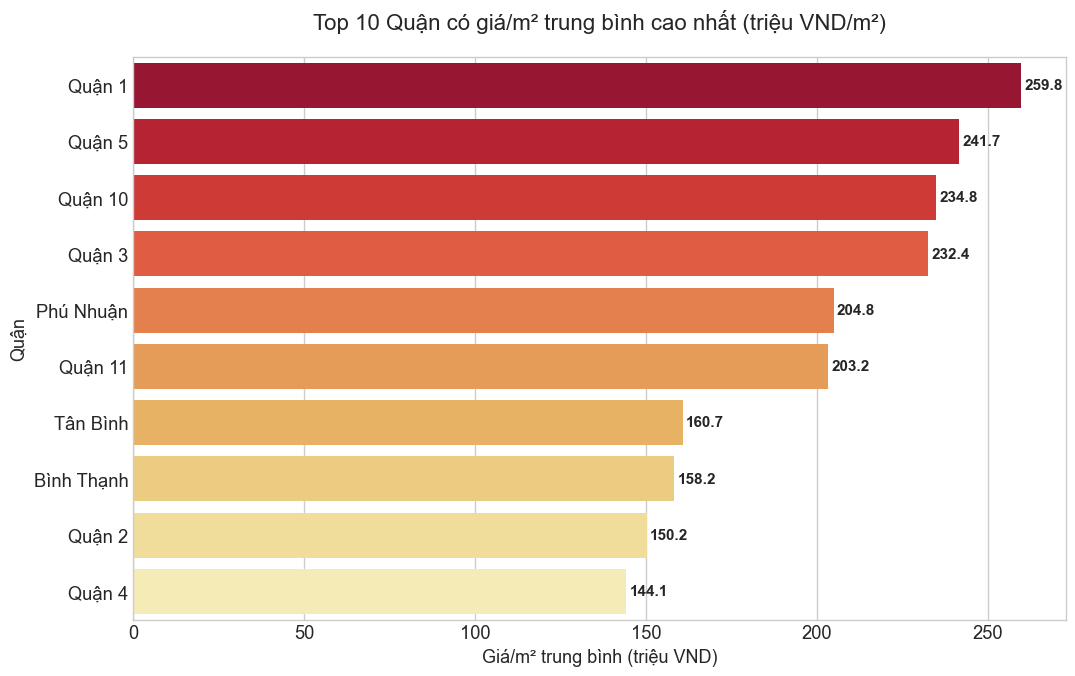

In [102]:
top_price_m2 = (
    df.groupby("district")["price(m2)"].mean().sort_values(ascending=False).head(10)
)

plt.figure(figsize=(11, 7))
ax = sns.barplot(x=top_price_m2.values, y=top_price_m2.index, palette="YlOrRd_r")

plt.title(
    "Top 10 Quận có giá/m² trung bình cao nhất (triệu VND/m²)", fontsize=16, pad=20
)
plt.xlabel("Giá/m² trung bình (triệu VND)", fontsize=13)
plt.ylabel("Quận", fontsize=13)

for i, v in enumerate(top_price_m2.values):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Top 10 Quận có giá/m² trung bình cao nhất (triệu VND/m²)

Biểu đồ xếp hạng Top 10 quận theo **giá trung bình mỗi m²** cho thấy **sự thống trị tuyệt đối** của các quận trung tâm nội thành truyền thống tại TP.HCM. Giá đất/m² giảm dần rõ rệt khi ra khỏi lõi trung tâm, phản ánh giá trị vị trí, tiện ích hạ tầng, lịch sử và nhu cầu cao cấp tập trung mạnh mẽ ở khu vực nội thành.

#### Nhận xét chính

- **Quận có giá cao nhất & dẫn đầu vượt trội**:  
  **Quận 1** đạt **259,8 triệu VND/m²** – **cao nhất toàn bộ Top 10 và toàn thị trường**, vượt xa các quận còn lại và khẳng định vị thế trung tâm tài chính – thương mại – cao cấp hàng đầu TP.HCM.

- **Nhóm dẫn đầu (trên 230 triệu/m²)** – Lõi trung tâm lịch sử:  
  - **Quận 1**: **259,8**  
  - **Quận 5**: **241,7**  
  - **Quận 10**: **234,8**  
  - **Quận 3**: **232,4**  
  → **4 quận này tạo thành nhóm giá trị đất đai cao nhất**, đại diện cho trung tâm truyền thống với vị trí đắc địa, mật độ dân cư cao, tiện ích đầy đủ và nhu cầu bất động sản cao cấp mạnh mẽ.

- **Nhóm cao cấp (trên 200 triệu/m²)** – Nội thành mở rộng:  
  - **Phú Nhuận**: **204,8**  
  - **Quận 11**: **203,2**  
  → Hai quận này vẫn duy trì mức giá **rất cao**, nhờ vị trí liền kề trung tâm, hạ tầng đồng bộ và sức hút đầu tư lâu dài.

- **Nhóm trung-cao (150–160 triệu/m²)** – Vùng chuyển tiếp gần trung tâm:  
  - **Tân Bình**: **160,7**  
  - **Bình Thạnh**: **158,2**  
  - **Quận 2** (nay thuộc TP. Thủ Đức): **150,2**  
  → Nhóm này đại diện cho các quận có **giá trị tốt**, kết nối chặt chẽ với trung tâm, phù hợp với phân khúc cao cấp và trung cao cấp, nhưng chưa đạt mức lõi nội thành.

- **Quận thấp nhất trong Top 10**:  
  **Quận 4** với **144,1 triệu VND/m²** – **thấp nhất trong nhóm Top 10**, nhưng vẫn cao hơn đáng kể so với hầu hết các quận/huyện ngoài Top 10 (thường dưới 120–130 triệu/m²).

#### Các chỉ số nổi bật
- **Khoảng cách giữa Quận 1 và Quận 4** (top 1 và top 10) khoảng **80%** (259,8 so với 144,1), minh chứng cho sự chênh lệch lớn ngay trong nội thành.  
- **Top 4 quận** (Quận 1, 5, 10, 3) đều **trên 230 triệu/m²**, tạo thành **nhóm lõi trung tâm** với giá trị vượt trội, cách biệt rõ rệt so với các quận còn lại trong Top 10.  
- Các quận thuộc **TP. Thủ Đức cũ** (như Quận 2) vẫn nằm trong nhóm trung-cao, cho thấy tiềm năng phát triển nhưng chưa đạt mức trung tâm truyền thống.

#### Kết luận tổng quan
Thị trường bất động sản TP.HCM thể hiện **sự phân cấp vị trí cực kỳ rõ nét** qua Top 10 quận có giá/m² cao nhất:  
- **Trung tâm lịch sử** (Quận 1, 3, 5, 10) thống trị tuyệt đối với mức giá trên 230 triệu/m², hướng đến phân khúc cao cấp, đầu tư và thương mại.  
- Các quận nội thành mở rộng và vùng chuyển tiếp (Phú Nhuận, Quận 11, Tân Bình, Bình Thạnh, Quận 2) duy trì giá trị cao, phù hợp với nhu cầu nhà ở chất lượng và đầu tư trung-dài hạn.  
- **Quận 4** dù thấp nhất Top 10 vẫn giữ mức giá cao hơn hẳn các khu vực ngoại thành, khẳng định giá trị của toàn bộ nội thành so với vùng ven.  

Sự chênh lệch này phản ánh đặc trưng điển hình của một đô thị lớn: **giá trị đất đai giảm mạnh theo khoảng cách từ trung tâm**, với lõi nội thành giữ vị thế độc tôn về giá trị bất động sản.

========================================================================================================================================================

### Biểu đồ: Top 10 Quận/Huyện có giá/m² trung bình thấp nhất (rẻ nhất – triệu VND/m²)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\4174331415.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




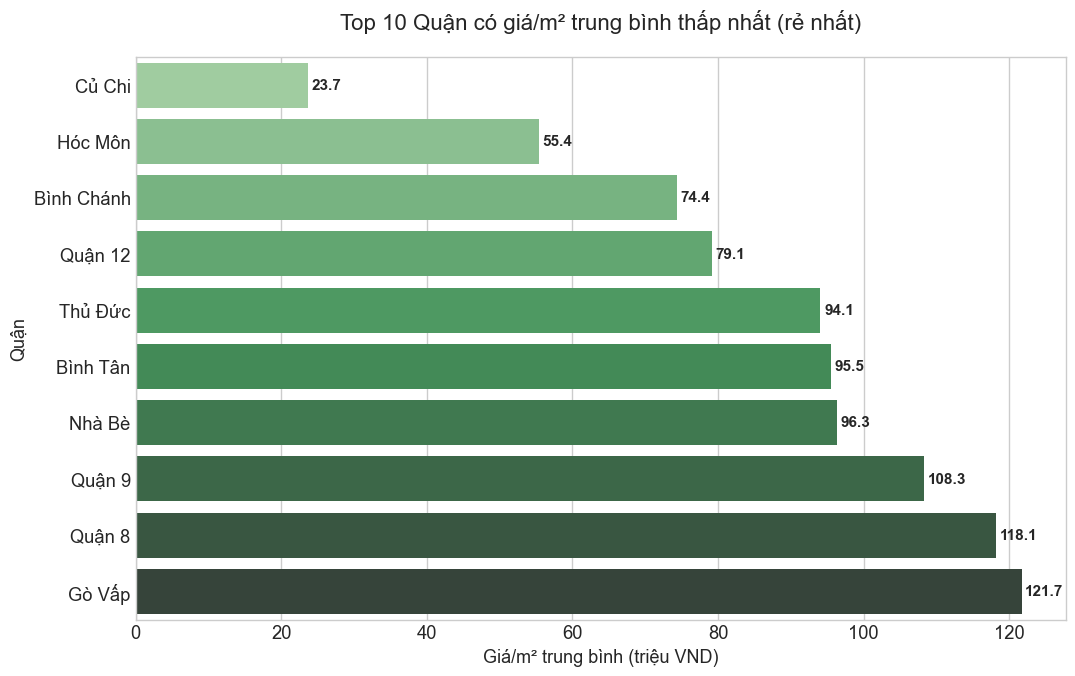

In [103]:
bottom_price_m2 = (
    df.groupby("district")["price(m2)"].mean().sort_values(ascending=True).head(10)
)

plt.figure(figsize=(11, 7))
ax = sns.barplot(x=bottom_price_m2.values, y=bottom_price_m2.index, palette="Greens_d")

plt.title("Top 10 Quận có giá/m² trung bình thấp nhất (rẻ nhất)", fontsize=16, pad=20)
plt.xlabel("Giá/m² trung bình (triệu VND)", fontsize=13)
plt.ylabel("Quận", fontsize=13)

for i, v in enumerate(bottom_price_m2.values):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Top 10 Quận/Huyện có giá/m² trung bình thấp nhất (rẻ nhất – triệu VND/m²)

Biểu đồ xếp hạng Top 10 quận/huyện có **giá trung bình mỗi m² thấp nhất** cho thấy **sự tập trung rõ rệt** vào các khu vực **ngoại thành và vùng ven** TP.HCM. Đây là những nơi có giá đất/m² dễ tiếp cận nhất, phù hợp với nhu cầu nhà ở phổ thông, đất nền rộng và đầu tư dài hạn, nơi quỹ đất còn dồi dào và mức độ đô thị hóa chưa cao bằng nội thành.

#### Nhận xét chính

- **Quận/Huyện rẻ nhất & dẫn đầu nhóm thấp**:  
  **Huyện Củ Chi** chỉ đạt **23,7 triệu VND/m²** – **thấp nhất toàn bộ dữ liệu**, cách biệt rất lớn so với các vị trí còn lại trong Top 10 và toàn thị trường, phản ánh đặc trưng vùng nông thôn ngoại ô.

- **Nhóm rẻ nhất (dưới 80 triệu/m²)** – Các huyện ngoại thành điển hình:  
  - **Củ Chi**: **23,7**  
  - **Hóc Môn**: **55,4**  
  - **Bình Chánh**: **74,4**  
  → **Ba huyện này chiếm vị trí rẻ nhất**, chủ yếu phù hợp với phân khúc **đất nền, nhà vườn, nhà ở giá rẻ** dành cho người mua có ngân sách hạn chế hoặc đầu tư dài hạn.

- **Nhóm thấp (80–100 triệu/m²)** – Vùng ven đang phát triển:  
  - **Quận 12**: **79,1**  
  - **Thủ Đức** (cũ): **94,1**  
  - **Bình Tân**: **95,5**  
  - **Nhà Bè**: **96,3**  
  → Nhóm này đại diện cho các quận/huyện **vùng ven đô thị hóa nhanh**, giá vẫn ở mức **trung bình thấp**, có tiềm năng tăng giá trong tương lai nhờ hạ tầng kết nối.

- **Nhóm cao nhất trong Top 10 rẻ (trên 100 triệu/m²)**:  
  - **Quận 9** (nay thuộc TP. Thủ Đức): **108,3**  
  - **Quận 8**: **118,1**  
  - **Gò Vấp**: **121,7**  
  → Đây là các quận có **lượng cung nhà rao bán lớn** (như Gò Vấp dẫn đầu toàn thị trường), nhưng giá/m² vẫn thuộc nhóm thấp so với trung tâm, giúp duy trì thanh khoản cao.

#### Các chỉ số nổi bật
- **Giá thấp nhất (Củ Chi)** chỉ bằng khoảng **19,5%** so với giá cao nhất trong Top 10 (Gò Vấp): 23,7 / 121,7 ≈ 0,195 – chênh lệch gần 5 lần ngay trong nhóm rẻ nhất.  
- **Top 3 rẻ nhất** đều là **huyện ngoại thành** (Củ Chi, Hóc Môn, Bình Chánh), với giá **dưới 75 triệu/m²**, tạo thành nhóm giá rẻ nhất toàn TP.HCM.  
- Các quận có **nguồn cung dồi dào** (Gò Vấp, Bình Tân, Quận 12) vẫn nằm trong Top 10 rẻ, cho thấy **giá/m² thấp** là yếu tố quan trọng hỗ trợ **thanh khoản cao** và sức hút với người mua phổ thông.

#### Kết luận tổng quan
Thị trường bất động sản TP.HCM thể hiện **sự phân cấp vị trí rõ nét** qua Top 10 quận/huyện có giá/m² thấp nhất:  
- **Ngoại thành và vùng ven** (Củ Chi, Hóc Môn, Bình Chánh, Quận 12, Bình Tân…) thống trị nhóm giá rẻ, phù hợp nhu cầu **nhà ở thực tế, đất nền giá phải chăng** và đầu tư dài hạn.  
- Các quận có **lượng cung lớn** (Gò Vấp, Bình Tân, Quận 12) nhờ giá/m² thấp đã trở thành điểm nóng về thanh khoản, phục vụ đa số người mua có thu nhập trung bình và trung bình thấp.  
- Sự chênh lệch giá/m² giữa nhóm rẻ nhất và trung tâm (có thể lên đến hơn 10 lần) là đặc trưng điển hình của đô thị lớn, nơi giá trị đất đai phụ thuộc mạnh mẽ vào khoảng cách đến trung tâm và mức độ phát triển hạ tầng.

==================================================================================================================================================

### Biểu đồ: Top 10 Đường phố đắt nhất (giá/m² trung bình cao nhất – triệu VND/m²)

C:\Users\huyma\AppData\Local\Temp\ipykernel_21312\3489053850.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




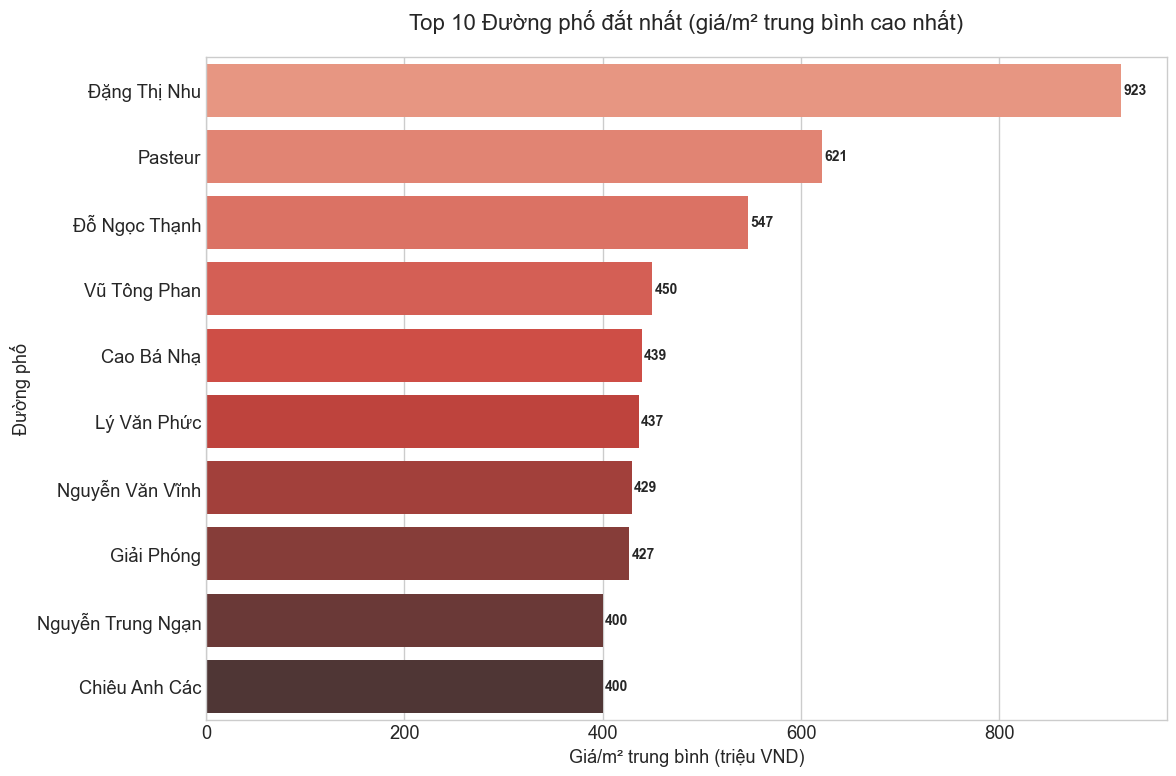

In [104]:
top_street_ppm = (
    df.groupby("street")["price(m2)"].mean().sort_values(ascending=False).head(10)
)

plt.figure(figsize=(12, 8))
ax = sns.barplot(x=top_street_ppm.values, y=top_street_ppm.index, palette="Reds_d")

plt.title("Top 10 Đường phố đắt nhất (giá/m² trung bình cao nhất)", fontsize=16, pad=20)
plt.xlabel("Giá/m² trung bình (triệu VND)", fontsize=13)
plt.ylabel("Đường phố", fontsize=13)

for i, v in enumerate(top_street_ppm.values):
    ax.text(v + 2, i, f"{v:.0f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

### Phân tích tổng quan biểu đồ: Top 10 Đường phố đắt nhất (giá/m² trung bình cao nhất – triệu VND/m²)

Biểu đồ xếp hạng Top 10 đường phố có **giá trung bình mỗi m² cao nhất** tại TP.HCM cho thấy **sự tập trung giá trị đất cực kỳ cao** tại một số tuyến đường nằm ở **lõi trung tâm nội thành**, chủ yếu thuộc Quận 1, Quận 3 và Quận 5. Đây là những con đường có vị trí đắc địa, mật độ thương mại – dịch vụ dày đặc, dân cư cao cấp và giá trị bất động sản vượt trội so với phần còn lại của thành phố.

#### Nhận xét chính

- **Đường phố đắt nhất & dẫn đầu vượt trội**:  
  **Đường Đặng Thị Nhu** đạt **923 triệu VND/m²** – **cao nhất toàn bộ Top 10 và toàn thị trường**, vượt xa các tuyến đường còn lại với khoảng cách rất lớn, khẳng định vị thế là con đường đắt đỏ bậc nhất TP.HCM.

- **Nhóm dẫn đầu (trên 500 triệu/m²)** – Lõi trung tâm cao cấp:  
  - **Đặng Thị Nhu**: **923**  
  - **Pasteur**: **621**  
  - **Đỗ Ngọc Thạnh**: **547**  
  → **Ba tuyến đường này thống trị nhóm cao nhất**, nằm ở vị trí lõi trung tâm, nơi tập trung các tòa nhà văn phòng, khách sạn, nhà hàng cao cấp và cư dân thượng lưu.

- **Nhóm cao (400–500 triệu/m²)** – Các tuyến đường trung tâm đắt đỏ:  
  - **Vũ Tông Phan**: **450**  
  - **Cao Bá Nhạ**: **439**  
  - **Lý Văn Phức**: **437**  
  - **Nguyễn Văn Vĩnh**: **429**  
  - **Giải Phóng**: **427**  
  - **Nguyễn Trung Ngạn**: **400**  
  - **Chiêu Anh Các**: **400**  
  → Nhóm này vẫn duy trì **mức giá rất cao**, chủ yếu thuộc các quận trung tâm truyền thống (Quận 1, Quận 3, Quận 5…), với giá trị thương mại và nhà ở cao cấp mạnh mẽ.

#### Các chỉ số nổi bật
- **Giá cao nhất (Đặng Thị Nhu)** gấp **hơn 2,3 lần** giá thấp nhất trong Top 10 (Nguyễn Trung Ngạn & Chiêu Anh Các): 923 / 400 ≈ **2,31 lần** – khoảng cách lớn ngay trong nhóm đắt nhất.  
- **Toàn bộ Top 10** đều đạt **từ 400 triệu VND/m² trở lên** – đây là ngưỡng giá thuộc hàng **đắt đỏ nhất** thị trường bất động sản nhà ở và thương mại tại TP.HCM.  
- Không có bất kỳ tuyến đường nào trong Top 10 dưới **400 triệu/m²**, cho thấy **ngưỡng “đường đắt”** đã được đẩy lên mức rất cao, phản ánh sự khan hiếm quỹ đất và nhu cầu cực kỳ mạnh ở khu vực trung tâm.

#### Kết luận tổng quan
Top 10 đường phố đắt nhất TP.HCM **tập trung hoàn toàn** vào **lõi nội thành** (chủ yếu Quận 1 và các quận lân cận), nơi giá/m² dao động từ **400–923 triệu VND**, thuộc phân khúc **siêu cao cấp** và **thương mại đỉnh cao**.  
- **Đặng Thị Nhu** dẫn đầu với mức giá gần 1 tỷ/m², tạo khoảng cách rõ rệt so với phần còn lại.  
- Các con đường này thường có đặc điểm: vị trí chiến lược, kết nối giao thông trung tâm, mật độ tiện ích cao cấp và quỹ đất cực kỳ hạn chế.  

Sự chênh lệch giá/m² giữa các tuyến đường trung tâm và các khu vực ngoại thành (thường dưới 100 triệu/m²) lên đến **hàng chục lần**, khẳng định **giá trị vị trí** là yếu tố quyết định nhất trong thị trường bất động sản TP.HCM hiện nay.

===========================================================================================================================================

### Biểu đồ: Số lượng nhà rao bán theo quận – Phân biệt có/không giảm giá  

In [114]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Đọc dữ liệu thật của bạn (thay đường dẫn phù hợp)
# df = pd.read_csv('du_lieu_nha_pho.csv')          # nếu là csv
# df = pd.read_excel('du_lieu_nha_pho.xlsx')       # nếu là excel

# Giả sử df đã được đọc, ta làm sạch Label
print("Trước khi làm sạch:")
print(df["Label"].value_counts(dropna=False))


# 2. Mã hóa Label: bất kỳ chuỗi nào chứa "GIẢM" hoặc "giảm" → 1, còn lại → 0
def encode_label(x):
    if pd.isna(x):  # xử lý NaN/rỗng
        return 0
    x_str = str(x).strip().upper()  # chuyển thành chuỗi, loại bỏ khoảng trắng, viết hoa
    if "GIẢM" in x_str or "GIAM" in x_str or "SALE" in x_str:  # linh hoạt hơn
        return 1
    return 0


df["Label_encoded"] = df["Label"].apply(encode_label)

print("\nSau khi mã hóa:")
print(df["Label_encoded"].value_counts())

# 3. Chọn các cột số + Label đã mã hóa
numeric_cols = [
    "price",
    "price(m2)",
    "bedroom",
    "bathroom",
    "area(m2)",
    "Label_encoded",
]

# Loại bỏ các hàng có giá trị thiếu ở cột số (nếu có)
df_clean = df[numeric_cols].dropna()

# 4. Tính ma trận tương quan
corr_matrix = df_clean.corr()



Trước khi làm sạch:
Label
0                      7872
GIẢM GIÁ | GIẢM GIÁ    1560
Name: count, dtype: int64

Sau khi mã hóa:
Label_encoded
0    7872
1    1560
Name: count, dtype: int64


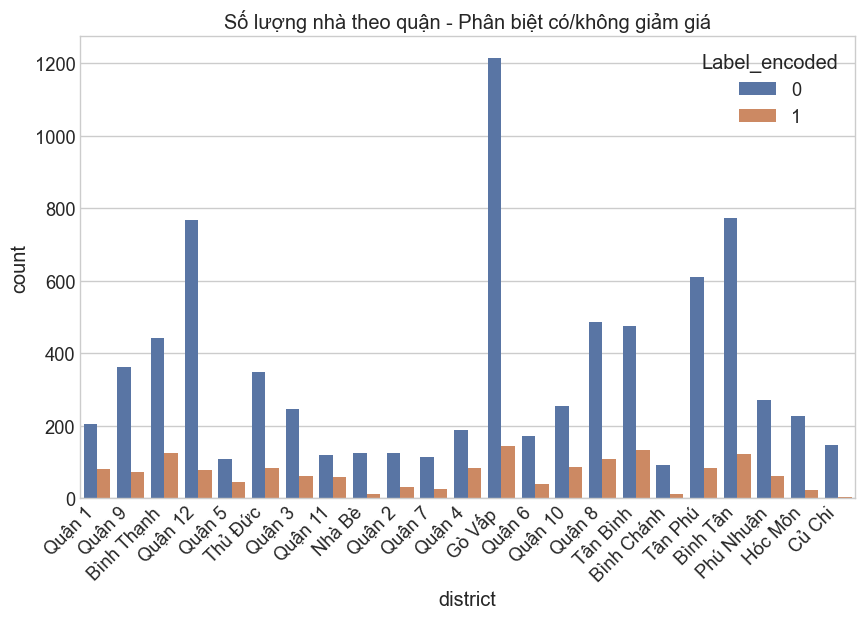

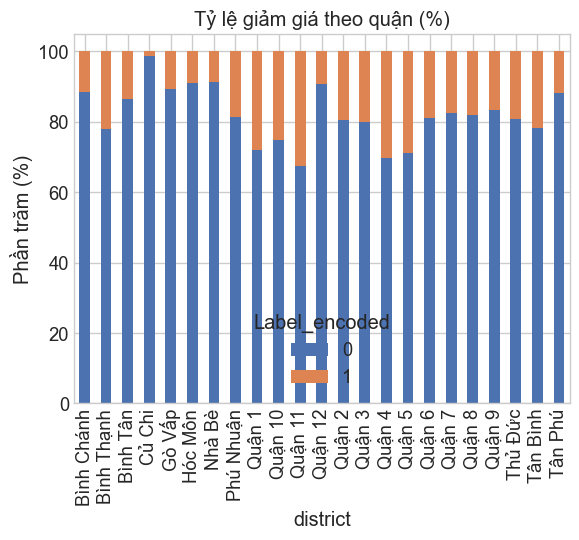

In [113]:
import seaborn as sns
import matplotlib.pyplot as plt

# Giả sử df đã có Label_encoded
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="district", hue="Label_encoded")
plt.title("Số lượng nhà theo quận - Phân biệt có/không giảm giá")
plt.xticks(rotation=45, ha="right")
plt.show()

# Hoặc tỷ lệ %
crosstab = pd.crosstab(df["district"], df["Label_encoded"], normalize="index") * 100
crosstab.plot(kind="bar", stacked=True)
plt.title("Tỷ lệ giảm giá theo quận (%)")
plt.ylabel("Phần trăm (%)")
plt.show()

### Phân tích tổng quan biểu đồ: Số lượng nhà rao bán theo quận – Phân biệt có/không giảm giá  
(Label_encoded: 0 = không giảm giá – màu xanh | 1 = có giảm giá – màu cam)

Biểu đồ cột phân tầng thể hiện rõ **phân bố số lượng nhà rao bán** theo quận/huyện tại TP.HCM, được chia thành hai nhóm chính:  
- **Không giảm giá** (màu xanh – Label 0): chiếm phần lớn nguồn cung.  
- **Có giảm giá** (màu cam – Label 1): chiếm tỷ lệ nhỏ hơn, nhưng nổi bật ở một số quận nhất định.  

Biểu đồ cho thấy **nguồn cung nhà ở tập trung mạnh** ở các quận ngoại thành và vùng ven, trong khi **tỷ lệ giảm giá** thay đổi rõ rệt theo khu vực, phản ánh mức độ cạnh tranh, thanh khoản và áp lực bán hàng tại từng quận.

#### Nhận xét chính

- **Quận dẫn đầu tổng lượng & vượt trội tuyệt đối**:  
  **Gò Vấp** đạt **khoảng 1.200 căn** – **cao nhất toàn bộ dữ liệu**, vượt xa các quận còn lại.  
  → Phần lớn là **không giảm giá** (màu xanh chiếm ưu thế áp đảo), cho thấy nguồn cung dồi dào, thanh khoản tốt và ít áp lực giảm giá.

- **Nhóm dẫn đầu tổng lượng (trên 600 căn)** – Nguồn cung lớn nhất:  
  - **Gò Vấp**: ~**1.200**  
  - **Quận 12**: ~**780**  
  - **Bình Tân**: ~**620**  
  - **Tân Phú**: ~**610**  
  → Các quận này chiếm **tỷ trọng lớn** trong toàn thị trường, chủ yếu thuộc nhóm **không giảm giá** (màu xanh chiếm phần lớn cột), phản ánh sức hút nhà ở phổ thông ở vùng ven.

- **Tỷ lệ có giảm giá (màu cam – Label 1)** – Phân tích theo nhóm quận:  
  - **Nhóm có tỷ lệ giảm giá cao tương đối** (màu cam chiếm tỷ lệ đáng kể):  
    **Bình Thạnh, Quận 8, Tân Bình, Bình Chánh, Phú Nhuận, Hóc Môn**  
    → Những khu vực này có **áp lực bán hàng cao hơn**, có thể do cạnh tranh mạnh, nguồn cung tăng nhanh hoặc nhu cầu giảm ở một số phân khúc.  
  - **Nhóm giảm giá thấp/ít nhất** (màu cam rất nhỏ hoặc gần như không đáng kể):  
    **Gò Vấp, Quận 12, Bình Tân, Quận 9, Thủ Đức**  
    → Nguồn cung lớn nhưng **ít phải giảm giá**, cho thấy thanh khoản tốt, nhu cầu ổn định và người bán tự tin giữ giá.

- **Nhóm có tổng lượng nhà thấp nhất** (dưới 250 căn):  
  **Củ Chi, Hóc Môn, Quận 1, Quận 3, Nhà Bè, Quận 2, Quận 7**  
  → Nguồn cung hạn chế, chủ yếu do quỹ đất khan hiếm (trung tâm) hoặc mức độ đô thị hóa thấp (ngoại thành xa).

- **Nhóm ít nhất về số lượng có giảm giá** (màu cam gần bằng 0):  
  **Củ Chi, Quận 1, Quận 3, Nhà Bè, Quận 2** và một số ngoại thành xa  
  → Gần như **không có hoặc rất ít** nhà rao giảm giá, có thể do:  
  - Khu vực cao cấp/trung tâm: người bán giữ giá cứng (Quận 1, Quận 3, Quận 2).  
  - Khu vực ngoại ô xa: nguồn cung thấp, ít cạnh tranh nên ít áp lực giảm.

#### Kết luận tổng quan
- **Thị trường nhà rao bán** tại TP.HCM **tập trung mạnh** vào các quận ngoại thành phổ thông (**Gò Vấp, Quận 12, Bình Tân, Tân Phú**) với nguồn cung lớn và **tỷ lệ giảm giá thấp**, cho thấy thanh khoản tốt và nhu cầu ổn định ở phân khúc giá phải chăng.  
- **Tỷ lệ giảm giá** (màu cam) nổi bật hơn ở một số quận nội thành mở rộng và vùng ven đang phát triển (**Bình Thạnh, Quận 8, Tân Bình, Phú Nhuận**), phản ánh cạnh tranh cao hơn hoặc áp lực bán hàng ở phân khúc trung cấp.  
- Các quận **trung tâm cao cấp** (Quận 1, Quận 3) và **ngoại thành xa** (Củ Chi) có nguồn cung thấp và **gần như không giảm giá**, phù hợp với đặc thù: quỹ đất khan hiếm hoặc nhu cầu đầu tư dài hạn.  

Biểu đồ này nhấn mạnh rằng **giá nhà không giảm** chủ yếu ở các khu vực có **nguồn cung dồi dào và thanh khoản tốt**, trong khi **áp lực giảm giá** xuất hiện rõ hơn ở các quận có sự cạnh tranh cao hoặc biến động nhu cầu.